# Homework 6 — Treatment effects

## tl;dr

| Quiz question | Matched estimate | Closest answer |
|---|---:|---|
| Q1: Average treatment effect (ATE) | 1.695270 | **D — 1.695** |
| Q2: Average treatment effect on the treated (ATT) | 1.846409 | **D — 1.846** |
| Q3: Average treatment effect on the untreated (ATU) | 1.549477 | **C — 1.549** |
| Q4: Optimal treatment effect (maximum among untreated) | 2.172470 | **A — 2.172** |

Each observation receives one nearest counterfactual from the opposite treatment group, matched on Z with replacement. The notebook includes all four quiz questions and choices, calculations, and Homework Reflection 6 with executable code.

## Context & Methods

**Source:** `Homework Instructions + Data Files/homework_6.1.csv`. X indicates treatment, Y is the observed outcome, and Z is the confounder. The supplied Week 6 quiz asks for one nearest opposite-group item per observation using Z. Keep the effect direction **treated minus untreated** in both matching directions.

For a treated observation i, estimate its effect as $\hat\tau_i=Y_i-Y_{m_0(i)}$; for an untreated observation i, estimate its effect as $\hat\tau_i=Y_{m_1(i)}-Y_i$. Here $m_0(i)$ and $m_1(i)$ identify the nearest untreated and treated observations respectively.

$$\widehat{ATT}=\frac{1}{n_1}\sum_{X_i=1}\hat\tau_i,\quad
\widehat{ATU}=\frac{1}{n_0}\sum_{X_i=0}\hat\tau_i,$$
$$\widehat{ATE}=\frac{n_1\widehat{ATT}+n_0\widehat{ATU}}{n_1+n_0},\quad
\widehat{\tau}_{optimal}=\max_{X_i=0}\hat\tau_i.$$

### Key Assumptions

- One-dimensional Euclidean matching minimizes $|Z_i-Z_j|$. Match with replacement, without a caliper or trimming, as required by the quiz.
- Give every original observation equal weight for ATE. Reused counterfactuals remain in each relevant pair; the pairs need not be reciprocal.
- Causal interpretation additionally requires consistency, no interference, sufficient overlap, and no unmeasured confounding after conditioning on Z. Nearest matching also approximates, rather than observes, individual counterfactual outcomes.
- “Optimal treatment effect” follows the quiz's maximum-among-untreated definition. Reflection 6 calls this quantity “Marginal Treatment Effect”; that course usage is retained in the reflection, rather than asserting that a sample maximum is the usual econometric MTE.

Run top-to-bottom with Python 3 and `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `IPython`. Source discovery works from the project root or its subfolders.

## Data

### 1. Set up and locate the source

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

pd.set_option('display.precision', 6)
plt.rcParams.update({
    'figure.figsize': (9, 4.8), 'figure.dpi': 110, 'font.size': 11,
    'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#E5E7EB', 'axes.axisbelow': True,
    'text.color': '#1F2937', 'axes.labelcolor': '#1F2937',
})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'

def locate_source(filename):
    for folder in (Path.cwd(), *Path.cwd().parents):
        for candidate in (folder / 'Homework Instructions + Data Files' / filename,
                          folder / filename):
            if candidate.is_file():
                return candidate.resolve()
    raise FileNotFoundError(f'Cannot locate {filename} in this project.')

SOURCE_PATH = locate_source('homework_6.1.csv')
print('Source:', SOURCE_PATH.relative_to(SOURCE_PATH.parent.parent))
print('SHA-256:', hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest())

Source: Homework Instructions + Data Files/homework_6.1.csv
SHA-256: f3d49964b094bbe5bf1ab09314aca6eae533850cdbba809b107feb2c5a6cde9e


### 2. Validate the data and split the groups

In [2]:
data = pd.read_csv(SOURCE_PATH)
required = ['X', 'Y', 'Z']
assert set(required).issubset(data.columns), 'Required columns are missing.'
assert all(pd.api.types.is_numeric_dtype(data[c]) for c in required)
assert np.isfinite(data[required].to_numpy()).all(), 'Missing or nonfinite values.'
assert set(data['X'].unique()) == {0, 1}, 'Both treatment groups must be present.'
data = data.reset_index(names='row_id')
treated = data.loc[data['X'] == 1].reset_index(drop=True)
untreated = data.loc[data['X'] == 0].reset_index(drop=True)

display(pd.DataFrame({
    'Check': ['Rows', 'Treated (X=1)', 'Untreated (X=0)', 'Missing values', 'Duplicate rows'],
    'Result': [len(data), len(treated), len(untreated),
               int(data[required].isna().sum().sum()), int(data[required].duplicated().sum())],
}))
display(data.head())

,Check,Result
0,Rows,1000
1,Treated (X=1),491
2,Untreated (X=0),509
3,Missing values,0
4,Duplicate rows,0


,row_id,Z,X,Y
0,0,0.548814,0,-0.823220
1,1,0.715189,1,0.842405
2,2,0.602763,1,0.898618
3,3,0.544883,0,-0.817325
4,4,0.423655,0,-0.635482


### 3. Inspect outcomes and overlap in Z

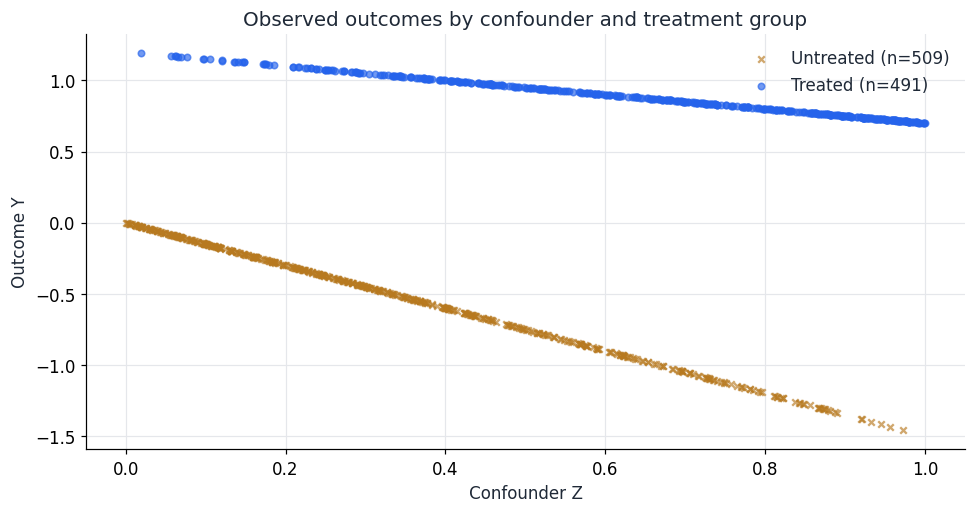

,n,min_Z,max_Z
X,,,
0,509,0.000546,0.972919
1,491,0.019193,0.999809


In [3]:
fig, ax = plt.subplots()
ax.scatter(untreated['Z'], untreated['Y'], s=18, color=GOLD, marker='x',
           alpha=0.65, label=f'Untreated (n={len(untreated)})')
ax.scatter(treated['Z'], treated['Y'], s=18, color=BLUE, marker='o',
           alpha=0.65, label=f'Treated (n={len(treated)})')
ax.set(title='Observed outcomes by confounder and treatment group',
       xlabel='Confounder Z', ylabel='Outcome Y')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
display(data.groupby('X').agg(n=('Y', 'size'), min_Z=('Z', 'min'), max_Z=('Z', 'max')))

The groups overlap over most of Z, but some observations near the endpoints lie outside the other group’s range. The quiz retains these observations and uses their nearest match; the match-distance summary below makes this limitation visible.

## Results

### 4. Match in both directions and calculate individual effects

In [4]:
def match_to_opposite_group(observed, counterfactual_group, observed_is_treated):
    model = NearestNeighbors(n_neighbors=1)
    model.fit(counterfactual_group[['Z']])
    distances, positions = model.kneighbors(observed[['Z']])
    matched = counterfactual_group.iloc[positions.ravel()].reset_index(drop=True)
    effects = (observed['Y'].to_numpy() - matched['Y'].to_numpy()
               if observed_is_treated else
               matched['Y'].to_numpy() - observed['Y'].to_numpy())
    return pd.DataFrame({
        'observed_row': observed['row_id'], 'observed_X': observed['X'],
        'observed_Z': observed['Z'], 'observed_Y': observed['Y'],
        'counterfactual_row': matched['row_id'], 'counterfactual_Z': matched['Z'],
        'counterfactual_Y': matched['Y'], 'Z_distance': distances.ravel(),
        'effect_Y1_minus_Y0': effects,
    })

treated_matches = match_to_opposite_group(treated, untreated, True)
untreated_matches = match_to_opposite_group(untreated, treated, False)
all_matches = pd.concat([treated_matches, untreated_matches], ignore_index=True)
ATT = treated_matches['effect_Y1_minus_Y0'].mean()
ATU = untreated_matches['effect_Y1_minus_Y0'].mean()
ATE = all_matches['effect_Y1_minus_Y0'].mean()
optimal_position = untreated_matches['effect_Y1_minus_Y0'].idxmax()
optimal_match = untreated_matches.loc[[optimal_position]]
optimal_effect = optimal_match['effect_Y1_minus_Y0'].iloc[0]

display(pd.DataFrame({
    'Observed group': ['Treated', 'Untreated'],
    'Number of pairs': [len(treated_matches), len(untreated_matches)],
    'Unique counterfactual rows': [treated_matches.counterfactual_row.nunique(),
                                 untreated_matches.counterfactual_row.nunique()],
    'Median Z distance': [treated_matches.Z_distance.median(), untreated_matches.Z_distance.median()],
    'Maximum Z distance': [treated_matches.Z_distance.max(), untreated_matches.Z_distance.max()],
}))
display(all_matches.head())

,Observed group,Number of pairs,Unique counterfactual rows,Median Z distance,Maximum Z distance
0,Treated,491,204,0.001087,0.026889
1,Untreated,509,203,0.001098,0.018647


,observed_row,observed_X,observed_Z,observed_Y,counterfactual_row,counterfactual_Z,counterfactual_Y,Z_distance,effect_Y1_minus_Y0
0,1,1,0.715189,0.842405,93,0.716327,-1.074491,0.001138,1.916896
1,2,1,0.602763,0.898618,485,0.604118,-0.906177,0.001354,1.804795
2,7,1,0.891773,0.754113,625,0.889794,-1.334690,0.001979,2.088804
3,8,1,0.963663,0.718169,122,0.956084,-1.434125,0.007579,2.152294
4,9,1,0.383442,1.008279,217,0.383464,-0.575196,0.000022,1.583475


### 5. Analysis of the four quiz questions

**Question 1. Which is closest to the average treatment effect?**

A: 2.014 · B: 1.583 · C: 1.832 · D: 1.695

**Answer: D — 1.695.** Average all 1,000 individual matched effects: **1.695270**. Equivalently, weight ATT by 491/1,000 and ATU by 509/1,000; a simple unweighted average of the two group means is not the requested ATE.

**Question 2. Which is closest to the average treatment effect on the treated?**

A: 1.620 · B: 1.503 · C: 1.714 · D: 1.846

**Answer: D — 1.846.** Average the 491 treated outcomes minus their nearest untreated counterfactual outcomes: **1.846409**. Untreated observations serve as matches but do not contribute their own effects to ATT.

**Question 3. Which is closest to the average treatment effect on the untreated?**

A: 1.689 · B: 1.843 · C: 1.549 · D: 2.305

**Answer: C — 1.549.** For each of the 509 untreated observations, subtract its observed outcome from its nearest treated counterfactual outcome, then average: **1.549477**. Keeping treated minus untreated preserves the sign.

**Question 4. Which is closest to the optimal treatment effect?**

A: 2.172 · B: 0.8935 · C: 1.480 · D: 1.134

**Answer: A — 2.172.** Take the maximum among the 509 untreated matched effects: **2.172470**. This uses a single untreated observation and its single treated counterfactual, as specified.

In [5]:
options = {
    'Q1': {'A': 2.014, 'B': 1.583, 'C': 1.832, 'D': 1.695},
    'Q2': {'A': 1.620, 'B': 1.503, 'C': 1.714, 'D': 1.846},
    'Q3': {'A': 1.689, 'B': 1.843, 'C': 1.549, 'D': 2.305},
    'Q4': {'A': 2.172, 'B': 0.8935, 'C': 1.480, 'D': 1.134},
}
estimates = {'Q1': ATE, 'Q2': ATT, 'Q3': ATU, 'Q4': optimal_effect}
answer_rows = []
for question, estimate in estimates.items():
    closest = min(options[question], key=lambda choice: abs(options[question][choice] - estimate))
    answer_rows.append({'Question': question, 'Computed result': estimate,
                        'Closest option': closest, 'Option value': options[question][closest]})
quiz_answers = pd.DataFrame(answer_rows)
display(quiz_answers)
print('Optimal pair (zero-based source row IDs; CSV line = row_id + 2):')
display(optimal_match)

,Question,Computed result,Closest option,Option value
0,Q1,1.695270,D,1.695
1,Q2,1.846409,D,1.846
2,Q3,1.549477,C,1.549
3,Q4,2.172470,A,2.172


Optimal pair (zero-based source row IDs; CSV line = row_id + 2):


,observed_row,observed_X,observed_Z,observed_Y,counterfactual_row,counterfactual_Z,counterfactual_Y,Z_distance,effect_Y1_minus_Y0
152,298,0,0.972919,-1.459379,951,0.973819,0.713091,0.000899,2.17247


### 6. Compare the effects and inspect heterogeneity

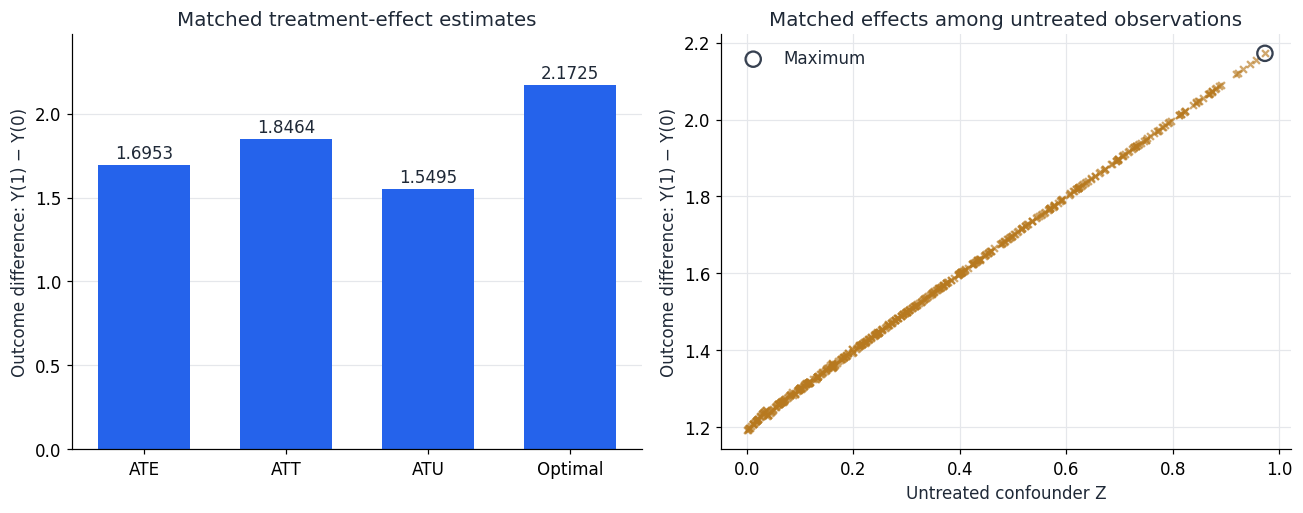

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
values = [ATE, ATT, ATU, optimal_effect]
axes[0].bar(['ATE', 'ATT', 'ATU', 'Optimal'], values, color=BLUE, width=0.65)
for index, value in enumerate(values):
    axes[0].text(index, value + 0.04, f'{value:.4f}', ha='center')
axes[0].set(title='Matched treatment-effect estimates', ylabel='Outcome difference: Y(1) − Y(0)',
            ylim=(0, max(values) + 0.3))
axes[0].grid(axis='x', visible=False)
axes[1].scatter(untreated_matches['observed_Z'], untreated_matches['effect_Y1_minus_Y0'],
                color=GOLD, marker='x', s=20, alpha=0.65)
axes[1].scatter(optimal_match['observed_Z'], optimal_match['effect_Y1_minus_Y0'],
                facecolors='none', edgecolors=DARK, s=100, linewidths=1.5, label='Maximum')
axes[1].set(title='Matched effects among untreated observations',
            xlabel='Untreated confounder Z', ylabel='Outcome difference: Y(1) − Y(0)')
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

ATT exceeds ATU, and the pooled ATE lies between them. The untreated matched effects rise with Z in this dataset, so the observed maximum occurs at an untreated Z near the upper endpoint. This is a sample matched estimate, not evidence that the same individual would yield the largest true effect in a new sample.

### 7. Verify the calculations independently

In [7]:
# Direct pairwise absolute distances independently verify every nearest match.
for observed, opposite, matches, is_treated in [
    (treated, untreated, treated_matches, True),
    (untreated, treated, untreated_matches, False),
]:
    pairwise_distance = np.abs(observed['Z'].to_numpy()[:, None] - opposite['Z'].to_numpy()[None, :])
    nearest_positions = pairwise_distance.argmin(axis=1)
    nearest_outcomes = opposite['Y'].to_numpy()[nearest_positions]
    direct_effect = (observed['Y'].to_numpy() - nearest_outcomes if is_treated
                     else nearest_outcomes - observed['Y'].to_numpy())
    np.testing.assert_allclose(matches['Z_distance'], pairwise_distance.min(axis=1))
    np.testing.assert_allclose(matches['effect_Y1_minus_Y0'], direct_effect)

weighted_ATE = (len(treated) * ATT + len(untreated) * ATU) / len(data)
np.testing.assert_allclose(ATE, weighted_ATE)
assert len(all_matches) == len(data)
assert all_matches['observed_row'].nunique() == len(data)
assert quiz_answers['Closest option'].tolist() == ['D', 'D', 'C', 'A']
print('Verified all nearest matches, effect signs, ATE weighting, and option selections.')

Verified all nearest matches, effect signs, ATE weighting, and option selections.


## Homework Reflection 6

### 1. What is a potential problem with comparing each untreated item to its counterfactual and taking the maximum difference?

Taking the maximum can select a large random error as well as a large true effect. If each estimated effect contains noise, searching many observations favors those whose errors happen to be positive, making the selected maximum prone to upward selection bias (the winner’s curse). A noisy outcome or poor counterfactual match can therefore determine the entire estimate, and the chosen observation may change in a new sample. The maximum is still the quiz’s requested statistic, but its value alone does not establish the largest true treatment effect.

### 2. Propose a solution and write code that implements it. Explain what the solution will do.

I use the 90th percentile of the untreated matched effects as the suggested upper-tail proxy. The code first calculates treated-counterfactual minus untreated-observed Y for every untreated item, then calls `np.quantile(effects, 0.90, method="linear")`. This summarizes a high point of the distribution without allowing one extreme item to set the result: **1.927962**, compared with the maximum **2.172470**. It reduces sensitivity to an isolated extreme value, but changes the target from a maximum to a percentile; it does not fully remove measurement error, matching bias, or unmeasured confounding. This proxy is for the reflection and does not replace Q4’s answer.

,Statistic,Estimated effect
0,Maximum (quiz Q4),2.172470
1,90th percentile (reflection proxy),1.927962


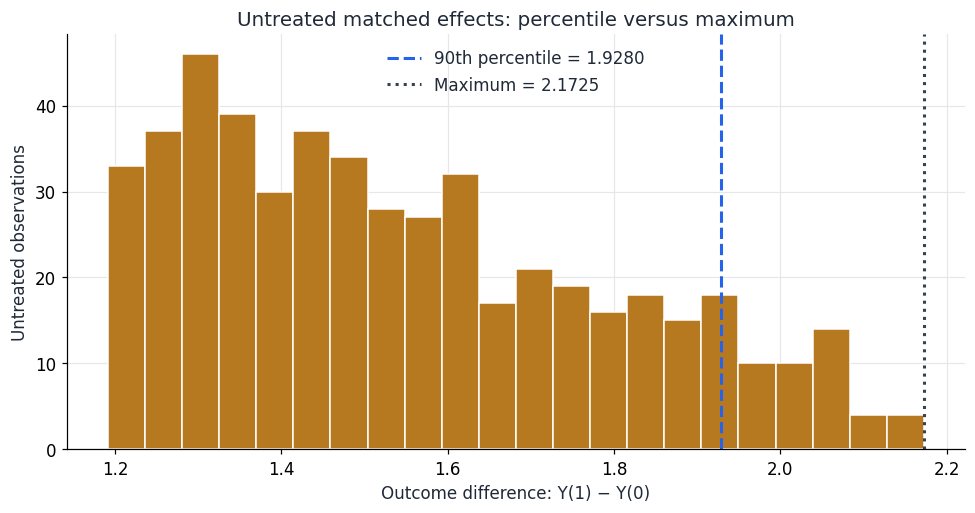

In [8]:
# Reflection remedy: prespecified upper-tail percentile among untreated effects.
effects = untreated_matches['effect_Y1_minus_Y0'].to_numpy()
upper_tail_proxy = np.quantile(effects, 0.90, method='linear')
reflection_summary = pd.DataFrame({
    'Statistic': ['Maximum (quiz Q4)', '90th percentile (reflection proxy)'],
    'Estimated effect': [effects.max(), upper_tail_proxy],
})
display(reflection_summary)

fig, ax = plt.subplots()
ax.hist(effects, bins=22, color=GOLD, edgecolor='white')
ax.axvline(upper_tail_proxy, color=BLUE, linestyle='--', linewidth=2,
           label=f'90th percentile = {upper_tail_proxy:.4f}')
ax.axvline(effects.max(), color=DARK, linestyle=':', linewidth=2,
           label=f'Maximum = {effects.max():.4f}')
ax.set(title='Untreated matched effects: percentile versus maximum',
       xlabel='Outcome difference: Y(1) − Y(0)', ylabel='Untreated observations')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Takeaways

**Quiz selections: Q1 D, Q2 D, Q3 C, Q4 A.** Matching in both directions is necessary to estimate the full-sample ATE and the effect on the untreated. The 90th-percentile reflection proxy summarizes the upper tail while avoiding reliance on the single largest observation; it estimates a different quantity from the quiz’s optimal effect.

### Reproducibility

The following cell records the Python and package versions used. Input identity is recorded with SHA-256 above; all matching and percentile calculations are deterministic.

In [9]:
print('Python:', platform.python_version())
for package in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'nbformat', 'nbclient']:
    print(f'{package}: {importlib.metadata.version(package)}')

Python: 3.13.5
numpy: 2.4.1
pandas: 3.0.0
matplotlib: 3.10.8
scikit-learn: 1.8.0
nbformat: 5.10.4
nbclient: 0.10.4
